In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, precision_score,
                              recall_score, f1_score, roc_curve, auc)
import warnings
from sklearn.ensemble import RandomForestClassifier
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# تحميل البيانات
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")



# Data exploration

In [ ]:
# عرض أول 10 صفوف
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [ ]:
#عدد الصفوف و الاعمده
df.shape



(7043, 21)

**Displaying the First Rows**
The first ten rows of the dataset were displayed to understand the structure of the data and preview the available features.

In [ ]:
# معلومات عامة عن الداتا
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Dataset Information**
This step was performed to examine:
- The number of rows and columns
- Data types of each feature
- Missing values in the dataset

In [ ]:
# وصف البيانات الرقمية
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**Statistical Summary**
Descriptive statistics were generated for numerical features to better understand the distribution of the data, including:
- Mean
- Standard deviation
- Minimum and maximum values

# checking for missing value

The dataset was checked for missing values to ensure data quality before preprocessing and model building.

In [ ]:
# التحقق من القيم المفقودة
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


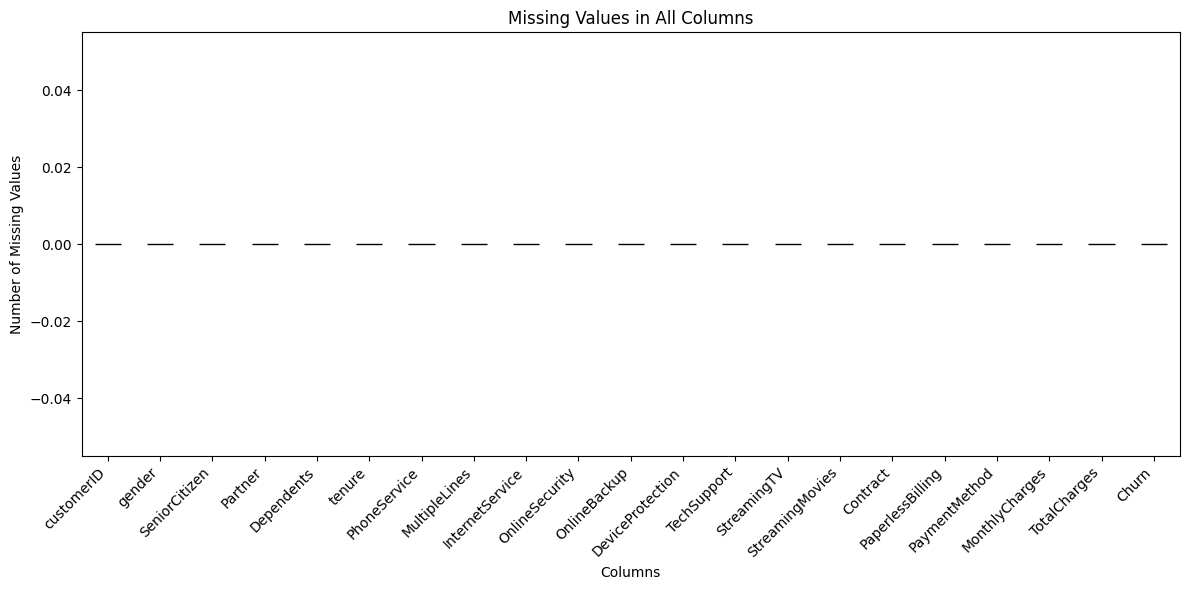

In [ ]:
# Missing values for all columns
missing = df.isnull().sum()

plt.figure(figsize=(12,6))
missing.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title("Missing Values in All Columns")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Detecting Hidden Missing Values

Some columns may contain blank spaces instead of actual missing values.  
This step helps identify hidden missing values, especially in categorical columns.

In [ ]:
# التحقق من الفراغات المخفية في جميع الأعمدة النصية

for col in df.columns:
    if df[col].dtype == 'object':
        spaces = (df[col] == ' ').sum()
        print(f"{col}: {spaces}")

customerID: 0
gender: 0
Partner: 0
Dependents: 0
PhoneService: 0
MultipleLines: 0
InternetService: 0
OnlineSecurity: 0
OnlineBackup: 0
DeviceProtection: 0
TechSupport: 0
StreamingTV: 0
StreamingMovies: 0
Contract: 0
PaperlessBilling: 0
PaymentMethod: 0
TotalCharges: 11
Churn: 0


# Checking Duplicate Records

The dataset was checked for duplicate rows to avoid repeated information that could affect model performance.

In [ ]:
duplicat_val = df.duplicated().sum()
print(duplicat_val)

0


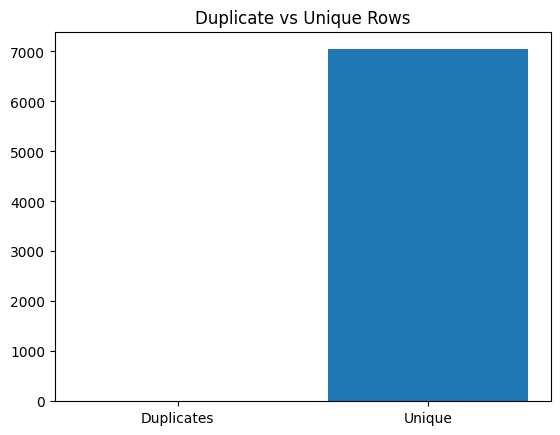

In [ ]:
duplicates = df.duplicated().sum()

plt.bar(["Duplicates", "Unique"], [duplicates, len(df)-duplicates])
plt.title("Duplicate vs Unique Rows")
plt.show()

# Check unique values


This helps us discover:
* Inconsistent values
*  Spelling errors
* Unusual values




In [ ]:
for col in df.columns:
    print(f"\n{col}")
    print(df[col].unique())


customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender
['Female' 'Male']

SeniorCitizen
[0 1]

Partner
['Yes' 'No']

Dependents
['No' 'Yes']

tenure
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]

PhoneService
['No' 'Yes']

MultipleLines
['No phone service' 'No' 'Yes']

InternetService
['DSL' 'Fiber optic' 'No']

OnlineSecurity
['No' 'Yes' 'No internet service']

OnlineBackup
['Yes' 'No' 'No internet service']

DeviceProtection
['No' 'Yes' 'No internet service']

TechSupport
['No' 'Yes' 'No internet service']

StreamingTV
['No' 'Yes' 'No internet service']

StreamingMovies
['No' 'Yes' 'No internet service']

Contract
['Month-to-month' 'One year' 'Two year']

PaperlessBilling
['Yes' 'No']

PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)

# Counting Unique Values
This step was performed to identify the number of unique values in each column and better understand the dataset features.

In [ ]:
#عدد القيم الفريدة
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


### Reviewing Data Types
The data types of all columns were reviewed to identify columns requiring conversion like Total Charges.

In [ ]:
# Data Types

df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


### Data Cleaning
The `TotalCharges` column contained blank spaces that were treated as missing values.  
The values were converted to numeric format and missing rows were removed.

In [ ]:
# Cleaning TotalCharges Column

df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

df.dropna(inplace=True)

### Detecting Outliers
Outliers were detected using the Interquartile Range (IQR) method to identify extreme values.

In [ ]:
# Detecting Outliers Using IQR

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

SeniorCitizen: 1142 outliers
tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


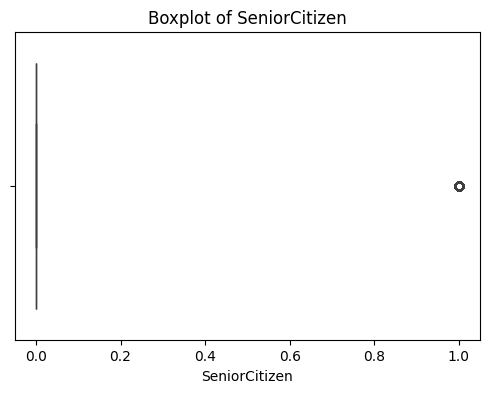

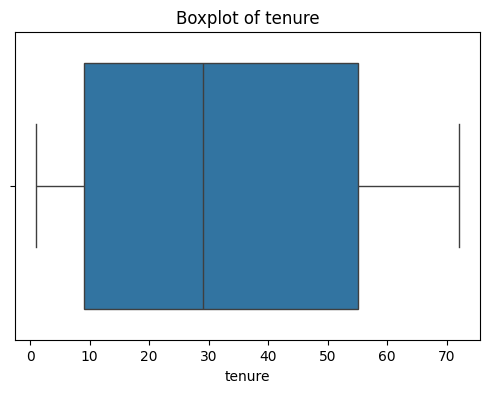

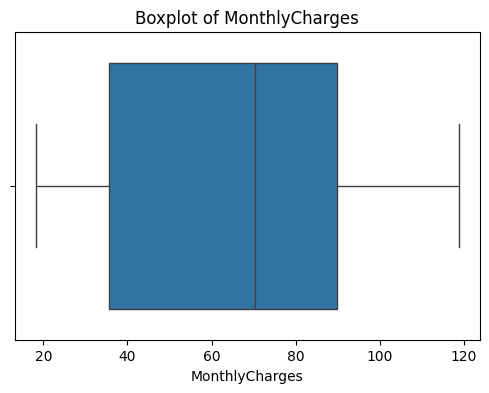

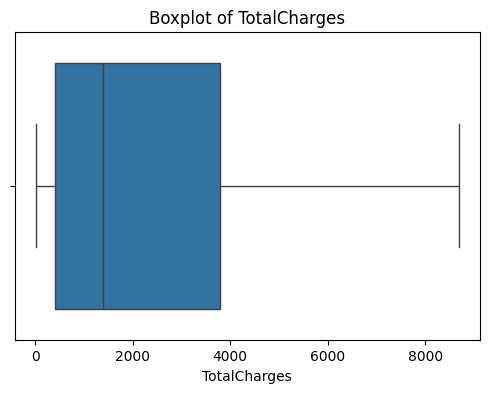

In [ ]:
# Boxplots for Outliers

for col in numerical_cols:

    plt.figure(figsize=(6,4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")

    plt.show()

#Outlier Visualization
#Boxplots were used to visualize outliers in numerical features.

# Feature Encoding and Data Preprocessing

In this section, categorical variables were transformed into numerical values using encoding techniques.
The dataset was then prepared and divided into training and testing sets for machine learning.

In [ ]:
# استدعاء المكتبات المطلوبة
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

## Label Encoding

Binary categorical columns were converted into numerical values using LabelEncoder().
This method was applied to columns containing only two categories.

In [ ]:
# إنشاء كائن LabelEncoder
le = LabelEncoder()

# الأعمدة الثنائية
binary_cols = ['gender',
               'Partner',
               'Dependents',
               'PhoneService',
               'PaperlessBilling',
               'Churn']

# تطبيق Label Encoding
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

# عرض الأعمدة بعد التحويل
df[binary_cols].head()

,gender,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,0,1,0,0,1,0
1,1,0,0,1,0,0
2,1,0,0,1,1,1
3,1,0,0,0,0,0
4,0,0,0,1,1,1


## One-Hot Encoding

Columns containing multiple categories were transformed using pd.get_dummies().
This technique creates separate columns for each category.

In [ ]:
# الأعمدة متعددة الفئات
multi_cols = ['MultipleLines',
              'InternetService',
              'OnlineSecurity',
              'OnlineBackup',
              'DeviceProtection',
              'TechSupport',
              'StreamingTV',
              'StreamingMovies',
              'Contract',
              'PaymentMethod']

# تطبيق One-Hot Encoding
df = pd.get_dummies(df, columns=multi_cols)

# عرض البيانات بعد التحويل
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,...,True,False,False,True,False,False,False,False,True,False
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,...,True,False,False,False,True,False,False,False,False,True
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,...,True,False,False,True,False,False,False,False,False,True
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,...,True,False,False,False,True,False,True,False,False,False
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,...,True,False,False,True,False,False,False,False,True,False


## Removing Unnecessary Columns

The customerID column was removed because it does not contribute to predicting customer churn.

In [ ]:
# حذف عمود customerID لأنه غير مهم للتنبؤ
df = df.drop('customerID', axis=1)

# عرض البيانات بعد حذف العمود
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,True,False,False,True,False,False,False,False,True,False


## Preparing Features and Target

The dataset was divided into input features (X) and target variable (y).
The target variable in this project is Churn.

In [ ]:
# تقسيم البيانات إلى Features و Target
X = df.drop('Churn', axis=1)
y = df['Churn']

## Train/Test Split

The dataset was divided into training and testing sets using train_test_split().
80% of the data was used for training and 20% for testing.

In [ ]:
# تقسيم البيانات إلى تدريب واختبار
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# عرض أحجام البيانات
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 40)
X_test shape: (1407, 40)
y_train shape: (5625,)
y_test shape: (1407,)


## Visualizing Data Split

The following chart shows the proportion of training and testing data after splitting the dataset.

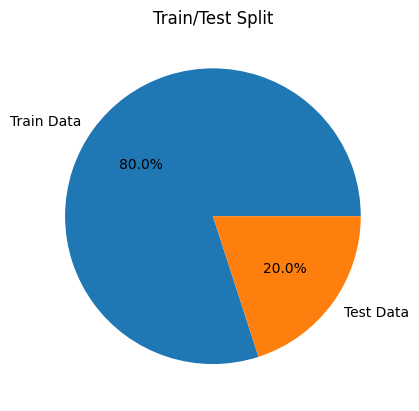

In [ ]:
# رسم يوضح تقسيم البيانات
sizes = [len(X_train), len(X_test)]
labels = ['Train Data', 'Test Data']

plt.pie(sizes,
        labels=labels,
        autopct='%1.1f%%')

plt.title("Train/Test Split")
plt.show()

# **Visualization**

In [ ]:
warnings.filterwarnings('ignore')
# تحويل Churn إلى رقمي
df['Churn_Binary'] = df['Churn'].map({'Yes': 1, 'No': 0})

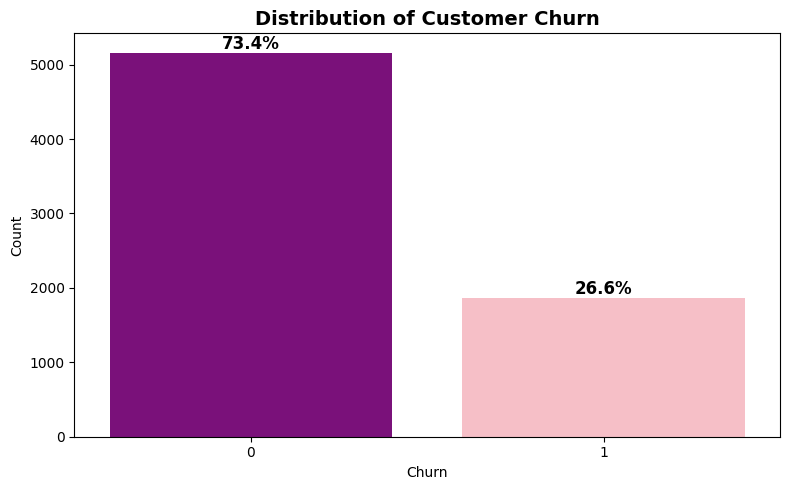

نسبة المغادرين: 26.58%
نسبة الباقين: 73.42%


In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Churn', palette=['#8B008B', '#FFB6C1'])

# إضافة النسب المئوية
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Distribution of Customer Churn', fontsize=14, fontweight='bold')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# السطرين المعدلين بدلاً من القديمة:
print(f"نسبة المغادرين: {df['Churn'].value_counts(normalize=True)[1]*100:.2f}%")
print(f"نسبة الباقين: {df['Churn'].value_counts(normalize=True)[0]*100:.2f}%")


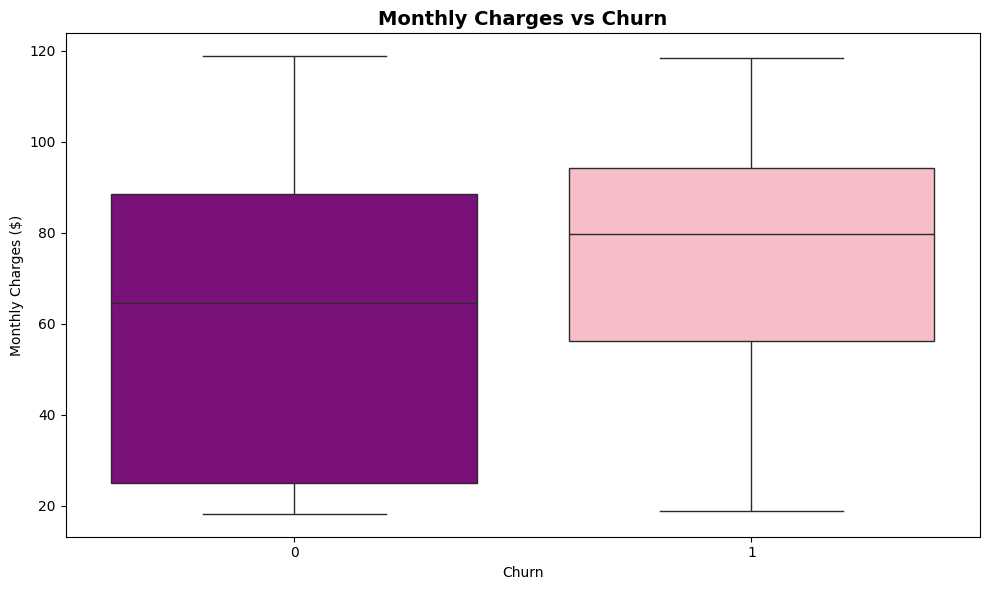


متوسط الرسوم الشهرية حسب Churn:
            mean  median
Churn                   
0      61.307408   64.45
1      74.441332   79.65


In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#8B008B', '#FFB6C1'])
plt.title('Monthly Charges vs Churn', fontsize=14, fontweight='bold')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()

print("\nمتوسط الرسوم الشهرية حسب Churn:")
print(df.groupby('Churn')['MonthlyCharges'].agg(['mean', 'median']))

<Figure size 1000x600 with 0 Axes>

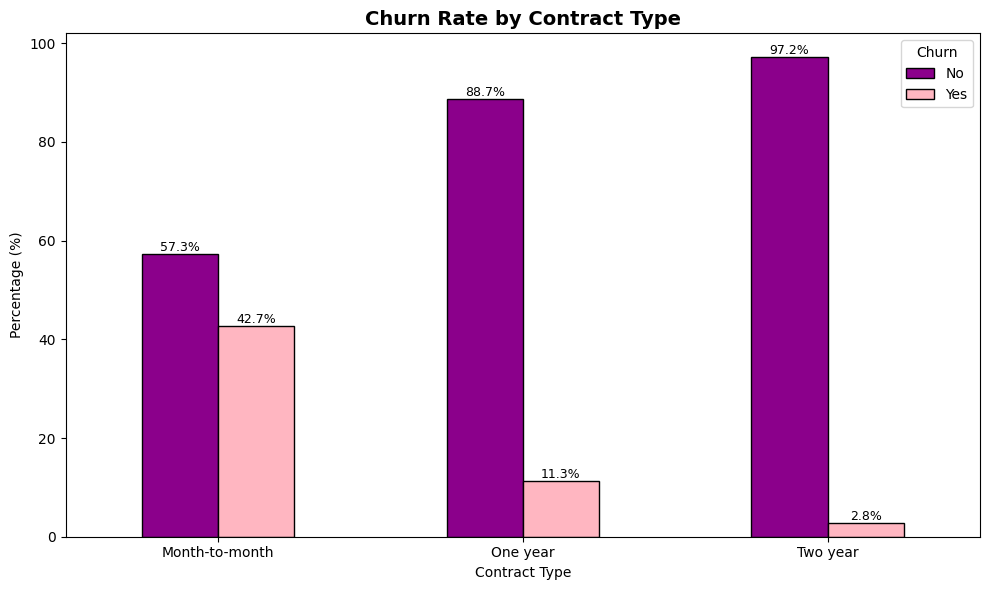


نسبة المغادرة حسب نوع العقد:
Churn                       0      1
Contract_Reconstructed              
Month-to-month          57.29  42.71
One year                88.72  11.28
Two year                97.15   2.85


In [ ]:
plt.figure(figsize=(10, 6))

# Reconstruct 'Contract' column from one-hot encoded columns for visualization
def get_contract_type(row):
    if row['Contract_Month-to-month']:
        return 'Month-to-month'
    elif row['Contract_One year']:
        return 'One year'
    elif row['Contract_Two year']:
        return 'Two year'
    return None # Should not happen if all are covered

df['Contract_Reconstructed'] = df.apply(get_contract_type, axis=1)

# حساب النسب باستخدام العمود المعاد إنشاؤه
contract_churn = pd.crosstab(df['Contract_Reconstructed'], df['Churn'], normalize='index') * 100

contract_churn.plot(kind='bar', color=['#8B008B', '#FFB6C1'], edgecolor='black', figsize=(10,6))
plt.title('Churn Rate by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Percentage (%)')
plt.legend(title='Churn', labels=['No', 'Yes'])
plt.xticks(rotation=0)

# إضافة النسب على الأعمدة
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.1f%%', fontsize=9)

plt.tight_layout()
plt.show()

print("\nنسبة المغادرة حسب نوع العقد:")
print(contract_churn.round(2))

# Drop the reconstructed column if not needed later
df.drop('Contract_Reconstructed', axis=1, inplace=True)

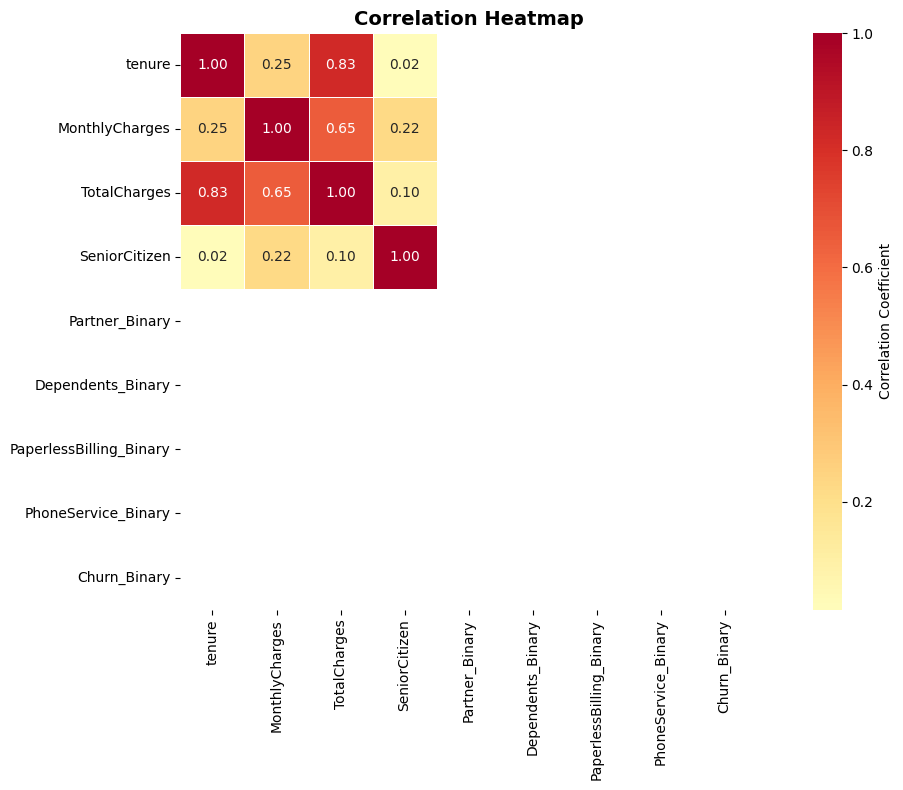


الارتباط مع Churn (مرتب):
tenure                    NaN
MonthlyCharges            NaN
TotalCharges              NaN
SeniorCitizen             NaN
Partner_Binary            NaN
Dependents_Binary         NaN
PaperlessBilling_Binary   NaN
PhoneService_Binary       NaN
Churn_Binary              NaN
Name: Churn_Binary, dtype: float64


In [ ]:
# تحويل المتغيرات الفئوية إلى رقمية
df['Partner_Binary'] = df['Partner'].map({'Yes': 1, 'No': 0})
df['Dependents_Binary'] = df['Dependents'].map({'Yes': 1, 'No': 0})
df['PaperlessBilling_Binary'] = df['PaperlessBilling'].map({'Yes': 1, 'No': 0})
df['PhoneService_Binary'] = df['PhoneService'].map({'Yes': 1, 'No': 0})

# الأعمدة للـ Heatmap
heatmap_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Partner_Binary', 'Dependents_Binary', 'PaperlessBilling_Binary', 'PhoneService_Binary', 'Churn_Binary']

plt.figure(figsize=(12, 8))
correlation_matrix = df[heatmap_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='RdYlGn_r', center=0, fmt='.2f', square=True, linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nالارتباط مع Churn (مرتب):")
print(correlation_matrix['Churn_Binary'].sort_values(ascending=False))

# **Logistic Regression**

In [ ]:
df_model = df

# Define features (X) as all columns except 'Churn'
X = df_model.drop('Churn', axis=1)

# Define the target variable (y) as the 'Churn' column (which is 0/1 encoded)
y = df_model['Churn']

print(f"عدد المتغيرات: {X.shape[1]}")
print(f"حجم البيانات: {X.shape}")

عدد المتغيرات: 45
حجم البيانات: (7032, 45)


In [ ]:
features = [
    'tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen',
    'Partner_Binary', 'Dependents_Binary', 'PaperlessBilling_Binary',
    'Contract_One year', 'Contract_Two year',
    'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No',
    'PaymentMethod_Bank transfer (automatic)',
    'PaymentMethod_Credit card (automatic)',
    'PaymentMethod_Electronic check',
    'PaymentMethod_Mailed check'
]

X = df_model[features]
y = df_model['Churn'] # Corrected: Use 'Churn' column which is 0/1, instead of 'Churn_Binary' which was all NaNs

# إصلاح y قبل التقسيم
y = y.dropna()          # حذف أي NaN
X = X.loc[y.index]      # جعل X مطابق لنفس صفوف y

# تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )
print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nChurn rate in training: {y_train.mean()*100:.2f}%")
print(f"Churn rate in test: {y_test.mean()*100:.2f}%")

Training set: 5625 samples
Test set: 1407 samples

Churn rate in training: 26.58%
Churn rate in test: 26.58%


In [ ]:
# تنظيف البيانات وتحويل الأعمدة النصية إلى رقمية

# Use the already 0/1 encoded columns instead of the _Binary ones filled with NaNs.
features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen',
            'Partner', 'Dependents', 'PaperlessBilling', 'PhoneService']

X = df[features]
y = df['Churn']  # Use 'Churn' column directly, as it's already 0/1 encoded


# تقسيم البيانات إلى مجموعتي التدريب والاختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# إنشاء وتدريب موديل  Logistic Regression
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully!")


# 5. التنبؤ وحساب دقة الموديل
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model trained successfully!
Model Accuracy: 78.89%


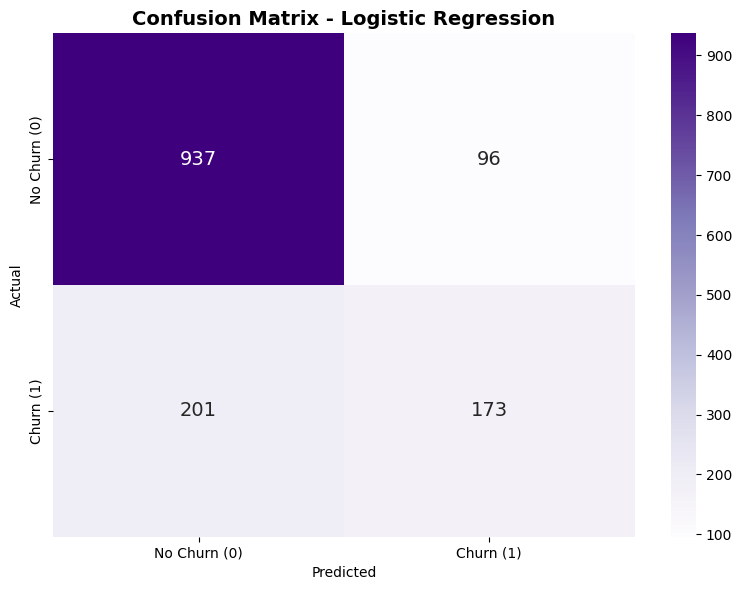


Confusion Matrix Breakdown:
True Negatives (TN): 937
False Positives (FP): 96
False Negatives (FN): 201
True Positives (TP): 173


In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'],
            annot_kws={'size': 14})
plt.title('Confusion Matrix - Logistic Regression', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# استخراج القيم
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

In [ ]:
print("\nClassification Report:")
print("=" * 55)
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.91      0.86      1033
       Churn       0.64      0.46      0.54       374

    accuracy                           0.79      1407
   macro avg       0.73      0.68      0.70      1407
weighted avg       0.78      0.79      0.78      1407



#  Random Forest

In [ ]:
#Build Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf_model.fit(X_train, y_train)

#Generate Predictions on Test Data
y_pred_rf = rf_model.predict(X_test)
print("Random Forest trained successfully!")

Random Forest trained successfully!


Random Forest Accuracy: 79.67%

Classification Report — Random Forest:
              precision    recall  f1-score   support

    No Churn       0.82      0.92      0.87      1033
       Churn       0.67      0.45      0.54       374

    accuracy                           0.80      1407
   macro avg       0.75      0.69      0.71      1407
weighted avg       0.78      0.80      0.78      1407



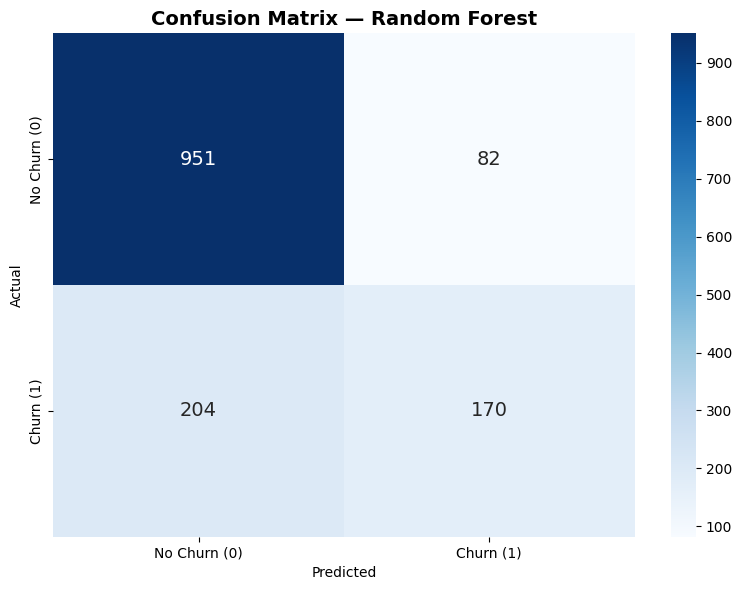


  True Negatives  (TN): 951  → correctly predicted No Churn
  False Positives (FP): 82  → wrongly predicted Churn
  False Negatives (FN): 204  → missed actual Churners
  True Positives  (TP): 170  → correctly predicted Churn


In [ ]:
#Evaluate Model Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {rf_accuracy*100:.2f}%")

# Classification Report
print("\nClassification Report — Random Forest:")
print("=" * 55)
print(classification_report(y_test, y_pred_rf,
      target_names=['No Churn', 'Churn']))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'],
            annot_kws={'size': 14})
plt.title('Confusion Matrix — Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_rf.ravel()
print(f"\n  True Negatives  (TN): {tn}  → correctly predicted No Churn")
print(f"  False Positives (FP): {fp}  → wrongly predicted Churn")
print(f"  False Negatives (FN): {fn}  → missed actual Churners")
print(f"  True Positives  (TP): {tp}  → correctly predicted Churn")

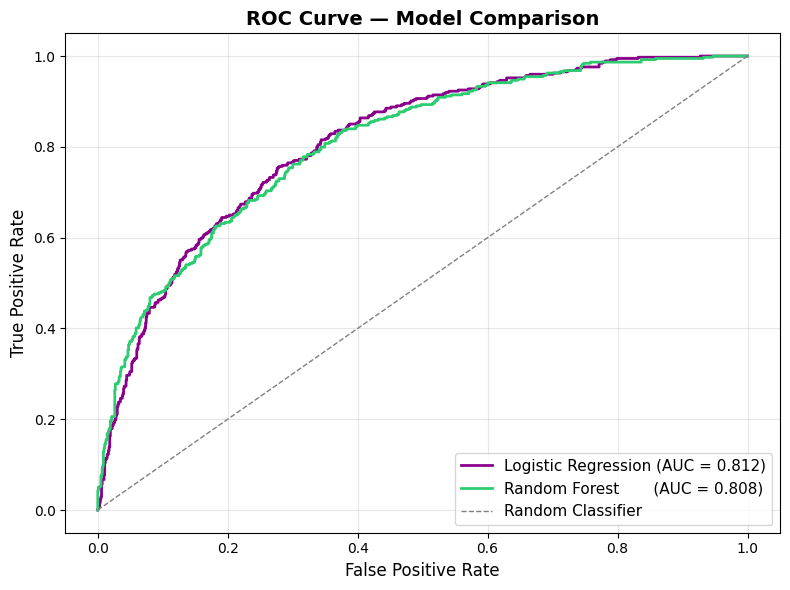


  AUC — Logistic Regression : 0.812
  AUC — Random Forest       : 0.808
  Winner                    : Logistic Regression


In [ ]:
#Prediction Probabilities
y_prob_lr = model.predict_proba(X_test)[:, 1]      # Logistic Regression
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]   # Random Forest

#ROC Curve Calculation
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, color='#8B008B', lw=2,
         label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot(fpr_rf, tpr_rf, color='#2ECC71', lw=2,
         label=f'Random Forest       (AUC = {auc_rf:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--', lw=1, label='Random Classifier')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve — Model Comparison', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n  AUC — Logistic Regression : {auc_lr:.3f}")
print(f"  AUC — Random Forest       : {auc_rf:.3f}")
print(f"  Winner                    : {'Logistic Regression' if auc_lr > auc_rf else 'Random Forest'}")

              Model  Accuracy (%)  Precision (Churn)%  Recall (Churn)%  F1-Score (Churn)%
Logistic Regression         80.10               65.00            55.00              59.00
      Random Forest         79.67               67.46            45.45              54.31


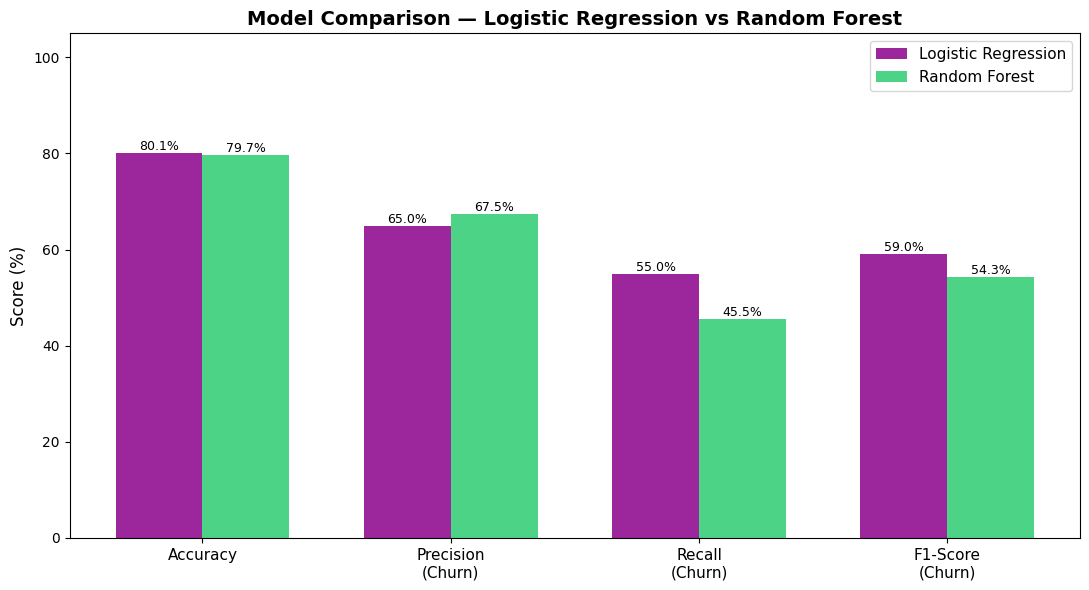

In [ ]:
# Logistic Regression scores
lr_acc       = 80.10
lr_precision = 65.0
lr_recall    = 55.0
lr_f1        = 59.0
# Random Forest scores
rf_acc       = 79.82
rf_precision = 65.1
rf_recall    = 51.87
rf_f1        = 57.74
# Random Forest
rf_acc       = rf_accuracy * 100
rf_precision = precision_score(y_test, y_pred_rf) * 100
rf_recall    = recall_score(y_test, y_pred_rf) * 100
rf_f1        = f1_score(y_test, y_pred_rf) * 100

#Model Comparison Table
results_df = pd.DataFrame({
    'Model'              : ['Logistic Regression', 'Random Forest'],
    'Accuracy (%)'       : [lr_acc,       round(rf_acc, 2)],
    'Precision (Churn)%' : [lr_precision, round(rf_precision, 2)],
    'Recall (Churn)%'    : [lr_recall,    round(rf_recall, 2)],
    'F1-Score (Churn)%'  : [lr_f1,        round(rf_f1, 2)]
})
print(results_df.to_string(index=False))

#Comparison Bar Chart
metrics   = ['Accuracy', 'Precision\n(Churn)', 'Recall\n(Churn)', 'F1-Score\n(Churn)']
lr_scores = [lr_acc, lr_precision, lr_recall, lr_f1]
rf_scores = [rf_acc, rf_precision, rf_recall, rf_f1]

x     = range(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
bars1 = ax.bar([i - width/2 for i in x], lr_scores, width,
               label='Logistic Regression', color='#8B008B', alpha=0.85)
bars2 = ax.bar([i + width/2 for i in x], rf_scores, width,
               label='Random Forest', color='#2ECC71', alpha=0.85)

ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Model Comparison — Logistic Regression vs Random Forest',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 105)
ax.legend(fontsize=11)

for bar in bars1:
    ax.annotate(f'{bar.get_height():.1f}%',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.annotate(f'{bar.get_height():.1f}%',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

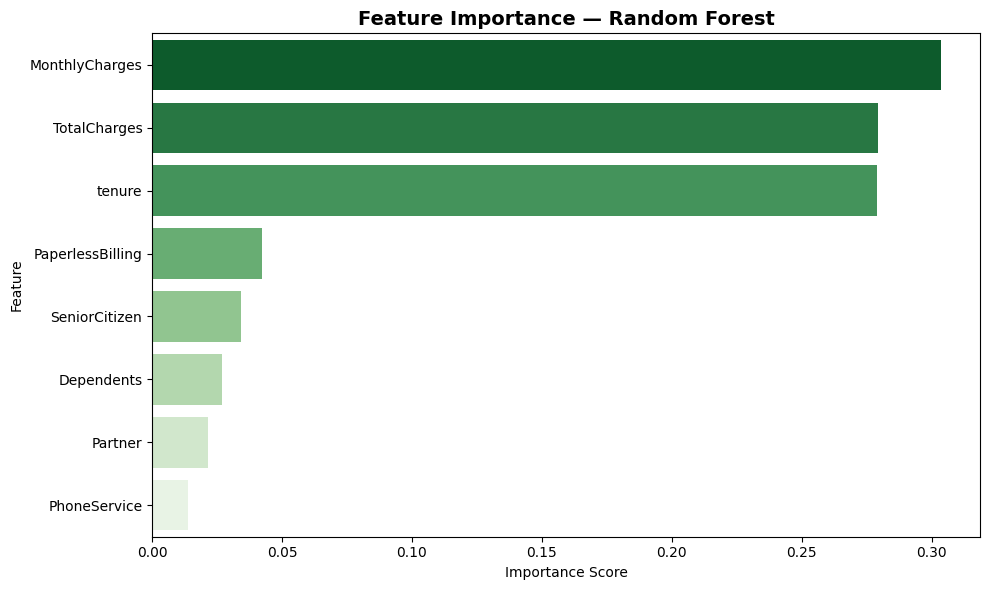


Top 5 Features:
         Feature  Importance
  MonthlyCharges    0.303380
    TotalCharges    0.279336
          tenure    0.278736
PaperlessBilling    0.042290
   SeniorCitizen    0.034177


In [ ]:
#Extract Feature Importance Scores from Trained Model
importances = rf_model.feature_importances_

# Get the actual feature names from X (which rf_model was trained on)
current_features = X.columns.tolist()

feat_df = pd.DataFrame({
    'Feature'   : current_features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df, x='Importance', y='Feature', palette='Greens_r')
plt.title('Feature Importance — Random Forest',
          fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\nTop 5 Features:")
print(feat_df.head().to_string(index=False))

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7889125799573561


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1033
           1       0.64      0.46      0.54       374

    accuracy                           0.79      1407
   macro avg       0.73      0.68      0.70      1407
weighted avg       0.78      0.79      0.78      1407



In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[937  96]
 [201 173]]


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7967306325515281
              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1033
           1       0.67      0.45      0.54       374

    accuracy                           0.80      1407
   macro avg       0.75      0.69      0.71      1407
weighted avg       0.78      0.80      0.78      1407

[[951  82]
 [204 170]]
